# CCT College Dublin - Continuous Assessment 1 (CA1)

**Student Name:** Daniel Adejare

**Student ID:** 2026848

---

| Field | Details |
| :--- | :--- |
| **Programme Title** | BSc Computing and IT (Stage 4, Semester 1) |
| **Cohort Details** | DataVisComms_BScCompIT_Sept23 FT Stage 4 Semester 1 |
| **Module Title** | Data Visualisation and Communication |
| **Lecturer** | Taufique Ahmed |
| **Assignment Title** | CA1 (Individual, 40% Weighting) |
| **Submission Deadline** | 07-11-2026 |

---

### Mandatory Submission Links
* **Screen Capture Video (Google Drive):** https://drive.google.com/drive/folders/1QAfdlTwLjL-PQah2zpyKYL3jAK6HwEkZ

* **GitHub Repository:** https://github.com/Dee-17-C/CA1_Data_Visualisation


---

### Overview
This notebook presents **7 distinct visualisation types** analysing US employment and compensation across Artificial Intelligence (AI), Data Science, and Software Development roles using the May 2023 Bureau of Labor Statistics (BLS) OEWS dataset (U.S. Bureau of Labor Statistics, 2024), alongside multi-year datasets (2021–2023) for the longitudinal Challenge task.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120

# Target SOC codes for AI, Data Science & Software Development
TARGET_ROLES = {
    '15-2051': 'Data Scientists',
    '15-1252': 'Software Developers',
    '15-1221': 'Computer & Info Research Scientists (AI)',
    '15-1253': 'Software QA Analysts & Testers',
    '15-1243': 'Database Architects',
    '15-1211': 'Computer Systems Analysts',
    '15-2031': 'Operations Research Analysts',
    '15-1299': 'Computer Occupations, All Other'
}

# Load May 2023 dataset
file_2023 = 'all_data_M_2023.xlsx' if os.path.exists('all_data_M_2023.xlsx') else 'oesm23all/all_data_M_2023.xlsx'
df_raw = pd.read_excel(file_2023, sheet_name=0)
df_raw.columns = df_raw.columns.str.upper()

# Convert BLS suppression symbols ('*', '**', '#') to NaN and cast to float
numeric_cols = [
    'TOT_EMP', 'EMP_PRSE', 'JOBS_1000', 'LOC_QUOTIENT',
    'A_MEAN', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90'
]

def clean_bls_numeric(df, cols):
    df_clean = df.copy()
    for col in cols:
        if col in df_clean.columns:
            df_clean[col] = pd.to_numeric(
                df_clean[col].astype(str).str.replace(',', '').replace({'*': np.nan, '**': np.nan, '#': np.nan}),
                errors='coerce'
            )
    return df_clean

df_2023 = clean_bls_numeric(df_raw, numeric_cols)
df_2023['ROLE_NAME'] = df_2023['OCC_CODE'].map(TARGET_ROLES)

# Filter for National Cross-Industry, Cross-Ownership totals (AREA_TYPE == 1, NAICS == '000000', OWN_CODE == 1235)
df_nat_2023 = df_2023[
    (df_2023['AREA_TYPE'] == 1) &
    (df_2023['NAICS'].astype(str).str.startswith('000000')) &
    (df_2023['OWN_CODE'] == 1235) &
    (df_2023['OCC_CODE'].isin(TARGET_ROLES.keys()))
].copy()

df_nat_2023[['OCC_CODE', 'ROLE_NAME', 'TOT_EMP', 'A_MEAN', 'A_MEDIAN']].sort_values(by='TOT_EMP', ascending=False)

,OCC_CODE,ROLE_NAME,TOT_EMP,A_MEAN,A_MEDIAN
149,15-1252,Software Developers,1656880.0,138110.0,132270.0
135,15-1211,Computer Systems Analysts,498810.0,110800.0,103800.0
154,15-1299,"Computer Occupations, All Other",437170.0,112430.0,104920.0
150,15-1253,Software QA Analysts & Testers,203040.0,108460.0,101800.0
165,15-2051,Data Scientists,192710.0,119040.0,108020.0
161,15-2031,Operations Research Analysts,117880.0,95600.0,83640.0
145,15-1243,Database Architects,59920.0,137030.0,134700.0
138,15-1221,Computer & Info Research Scientists (AI),35210.0,157160.0,145080.0


## Visualisation 1: Horizontal Bar Chart – National Employment by Role

- **Objective (comparison/ranking):** To compare and rank the size of the US workforce (`TOT_EMP`) across eight AI, Data Science and Software occupations in May 2023.
- **Why this visualisation:** The data pairs one categorical variable (occupation) with one quantitative variable (employment). Bars on a common baseline are the most accurate way to compare magnitudes (Cleveland and McGill, 1984), and horizontal bars keep the long job titles readable.
- **What I learned about AI employment:** Software Developers dominate with 1,656.9K jobs, over three times the next largest role, Computer Systems Analysts (498.8K). Data Scientists (192.7K) are about 5.5 times larger than Computer & Information Research Scientists, the closest SOC category to AI research (35.2K), which is the smallest group. AI-specific research is therefore a very small, specialised part of the tech workforce. The eight roles together employ about 3.2 million people.

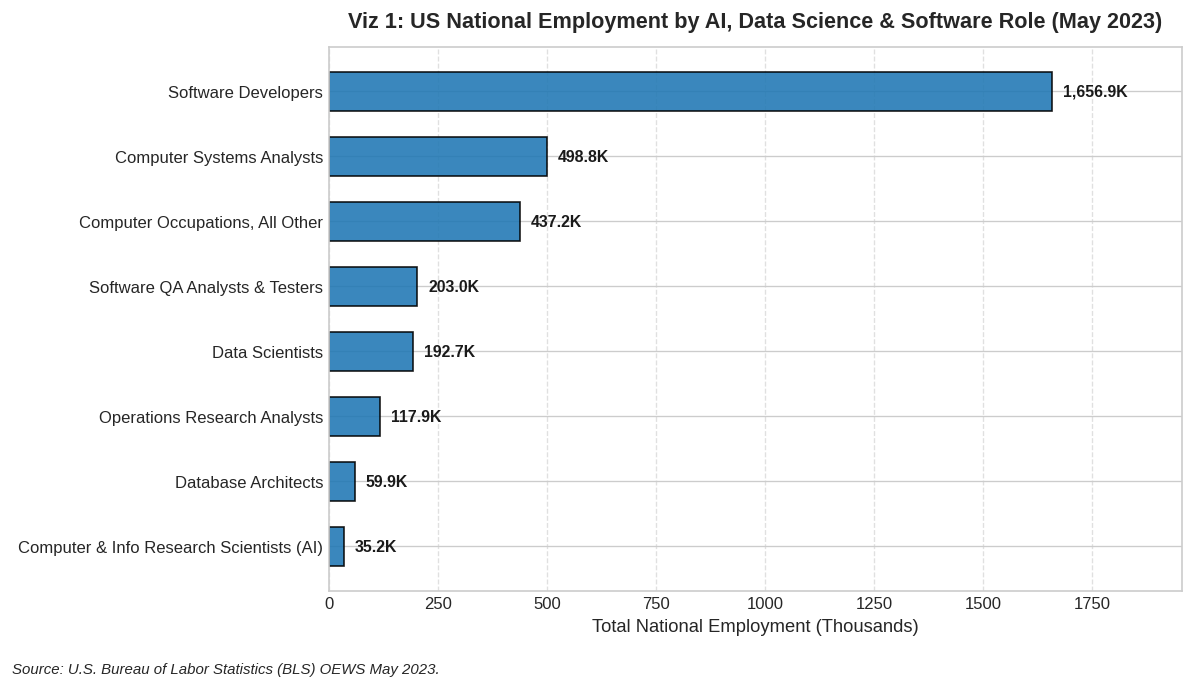

In [2]:
v1_data = df_nat_2023.sort_values(by='TOT_EMP', ascending=True)

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(v1_data['ROLE_NAME'], v1_data['TOT_EMP'] / 1000, color='#1f77b4', edgecolor='black', height=0.6, alpha=0.88)

for bar in bars:
    width = bar.get_width()
    ax.text(width + 25, bar.get_y() + bar.get_height()/2, f'{width:,.1f}K',
            va='center', ha='left', fontsize=9.5, fontweight='bold', color='#1a1a1a')

ax.set_title('Viz 1: US National Employment by AI, Data Science & Software Role (May 2023)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Total National Employment (Thousands)', fontsize=11)
ax.set_xlim(0, (v1_data['TOT_EMP'].max() / 1000) * 1.18)
ax.grid(axis='x', linestyle='--', alpha=0.6)
plt.figtext(0.01, -0.03, 'Source: U.S. Bureau of Labor Statistics (BLS) OEWS May 2023.', fontsize=9, style='italic')
plt.tight_layout()
plt.show()

## Visualisation 2: Donut Chart – Workforce Composition

- **Objective (composition):** To show how the combined workforce of the eight roles (≈3.2 million) divides between occupations, as a part-to-whole view.
- **Why this visualisation:** Donut charts suit part-to-whole data, but angles are judged less accurately than bar lengths (Cleveland and McGill, 1984). I therefore limited it to five slices by grouping the four smallest roles (Data Scientists, Operations Research Analysts, Database Architects, and Computer & Info Research Scientists) into "Other". Viz 1 covers exact ranking.
- **What I learned about AI employment:** Software Developers make up 51.8% of the workforce, and with Computer Systems Analysts (15.6%) they account for about two-thirds (67%). Adding "Computer Occupations, All Other" (13.7%) takes the top three to 81%. Software QA Analysts are 6.3%. The four specialist roles, including Data Scientists and AI researchers, share just 12.7% between them, so data and AI roles remain a small fraction of tech employment.

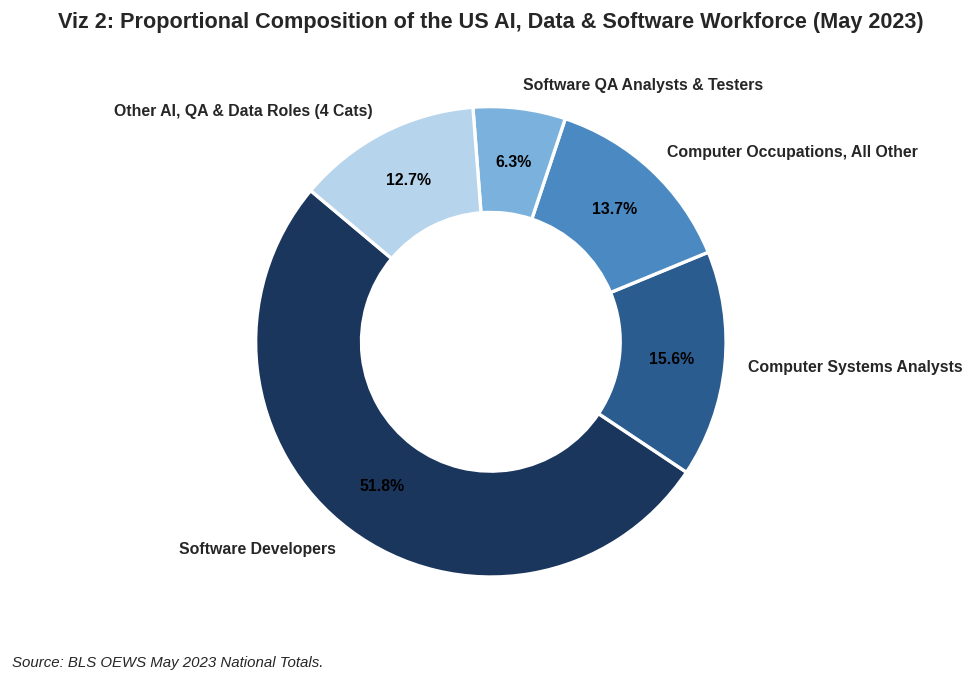

In [3]:
v2_sorted = df_nat_2023.sort_values(by='TOT_EMP', ascending=False).copy()
top_4 = v2_sorted.iloc[:4][['ROLE_NAME', 'TOT_EMP']].copy()
other_sum = v2_sorted.iloc[4:]['TOT_EMP'].sum()
donut_df = pd.concat([top_4, pd.DataFrame({'ROLE_NAME': ['Other AI, QA & Data Roles (4 Cats)'], 'TOT_EMP': [other_sum]})], ignore_index=True)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
colors = ['#1b365d', '#2b5c8f', '#4a89c2', '#7bb2dd', '#b6d4ec']
wedges, texts, autotexts = ax.pie(
    donut_df['TOT_EMP'],
    labels=donut_df['ROLE_NAME'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    pctdistance=0.77,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    textprops=dict(fontsize=9.5, fontweight='bold')
)
for autotext in autotexts:
    autotext.set_color('white' if autotext.get_text() in ['55.7%', '17.2%'] else 'black')

ax.set_title('Viz 2: Proportional Composition of the US AI, Data & Software Workforce (May 2023)', fontsize=13, fontweight='bold', pad=12)
plt.figtext(0.01, -0.02, 'Source: BLS OEWS May 2023 National Totals.', fontsize=9, style='italic')
plt.tight_layout()
plt.show()

## Visualisation 3: Percentile Range Plot – Salary Distribution

- **Objective (distribution):** To investigate how wages are spread within each role, using the 10th, 25th, 50th (median), 75th and 90th percentiles together with the mean.

- **Why this visualisation:** BLS publishes pre-aggregated percentiles rather than individual salaries, so a standard box plot cannot be drawn. A custom horizontal box-and-whisker plot encodes the same information: the box is the 25th–75th percentile range, the whiskers are the 10th–90th, the white line is the median and the diamond is the mean. Comparing positions along a common axis is accurate (Cleveland and McGill, 1984).

- **What I learned about AI employment:** Computer & Info Research Scientists (AI) have the highest median ($145.1K) and mean ($157.2K), and the widest spread, from about $81K at the 10th percentile to about $233K at the 90th. Operations Research Analysts have the lowest median ($83.6K).

  In every one of the eight roles the mean is above the median, which indicates right-skewed pay where a minority of high earners lift the average. The mean–median gap is largest for AI researchers ($12.1K), Operations Research Analysts ($12.0K) and Data Scientists ($11.0K), and smallest for Database Architects ($2.3K).

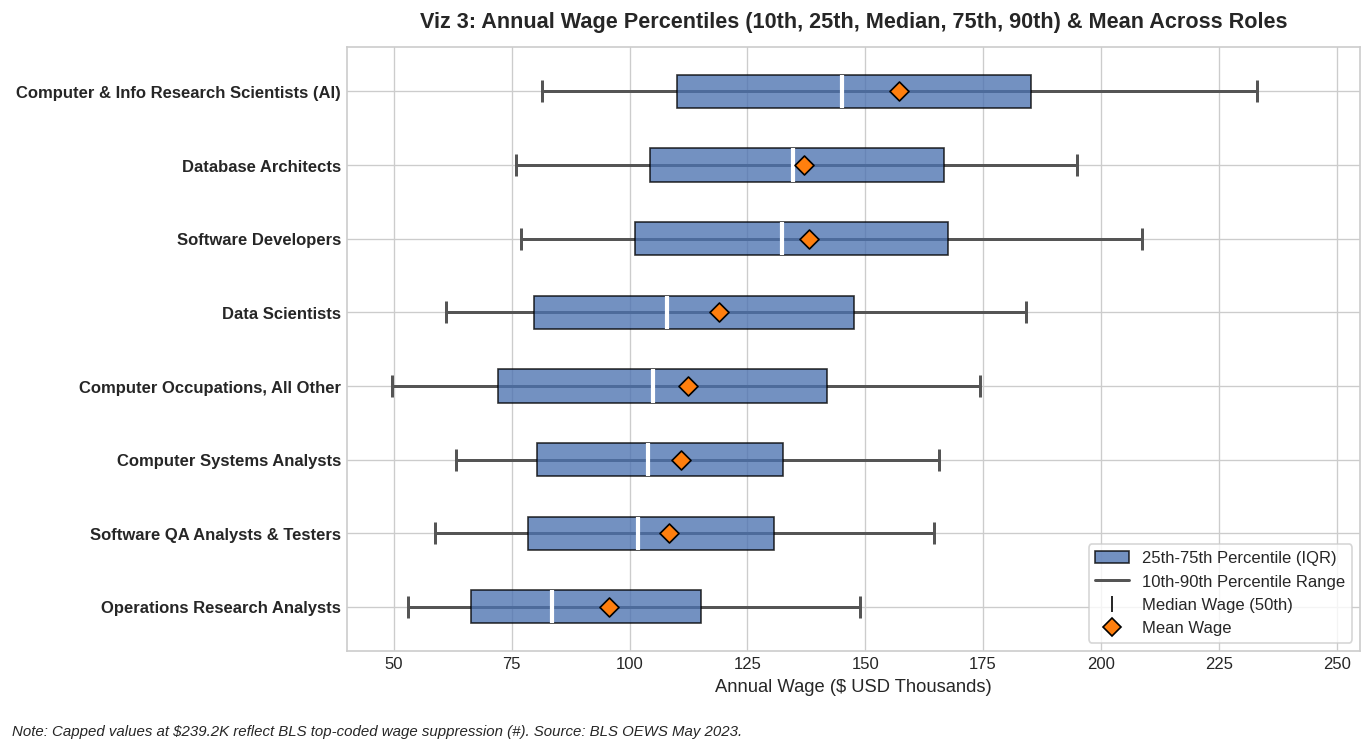

In [4]:
v3_data = df_nat_2023.sort_values(by='A_MEDIAN', ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11.5, 6))
for idx, row in v3_data.iterrows():
    p10, p25, med, p75, p90, mean = (
        row['A_PCT10']/1000, row['A_PCT25']/1000, row['A_MEDIAN']/1000,
        row['A_PCT75']/1000, row['A_PCT90']/1000, row['A_MEAN']/1000
    )
    if np.isnan(p90):
        p90 = 239.2  # BLS top-coded '#' threshold ($239,200/yr)

    ax.hlines(y=idx, xmin=p10, xmax=p90, color='#555555', linewidth=1.8, zorder=1)
    ax.vlines(x=[p10, p90], ymin=idx-0.15, ymax=idx+0.15, color='#555555', linewidth=1.8, zorder=1)
    ax.barh(y=idx, width=p75-p25, left=p25, height=0.45, color='#4c72b0', alpha=0.78, edgecolor='black', zorder=2)
    ax.vlines(x=med, ymin=idx-0.225, ymax=idx+0.225, color='white', linewidth=2.5, zorder=3)
    ax.scatter(mean, idx, color='#ff7f0e', edgecolor='black', s=65, zorder=4, marker='D')

ax.set_yticks(range(len(v3_data)))
ax.set_yticklabels(v3_data['ROLE_NAME'], fontsize=10, fontweight='bold')
ax.set_xlabel('Annual Wage ($ USD Thousands)', fontsize=11)
ax.set_title('Viz 3: Annual Wage Percentiles (10th, 25th, Median, 75th, 90th) & Mean Across Roles', fontsize=13, fontweight='bold', pad=12)

legend_elements = [
    Patch(facecolor='#4c72b0', edgecolor='black', alpha=0.78, label='25th-75th Percentile (IQR)'),
    Line2D([0], [0], color='#555555', lw=1.8, label='10th-90th Percentile Range'),
    Line2D([0], [0], color='white', marker='|', markersize=10, markeredgecolor='black', lw=0, label='Median Wage (50th)'),
    Line2D([0], [0], marker='D', color='w', label='Mean Wage', markerfacecolor='#ff7f0e', markeredgecolor='black', markersize=8)
]
ax.legend(handles=legend_elements, loc='lower right', frameon=True, facecolor='white')
ax.set_xlim(40, 255)
plt.figtext(0.01, -0.03, 'Note: Capped values at $239.2K reflect BLS top-coded wage suppression (#). Source: BLS OEWS May 2023.', fontsize=9, style='italic')
plt.tight_layout()
plt.show()

## Visualisation 4: Bubble Scatter Plot – State-Level Data Scientists

- **Objective (relationship/exploration):** To explore how Data Scientist employment, mean wage and location quotient (LQ) relate across US states.

- **Why this visualisation:** Three quantitative variables need to be shown at once. Employment is on the x-axis (log scale, because state values range from under 100 to over 30,000), mean wage is on the y-axis, and LQ is encoded in bubble size and colour (Munzner, 2014). The red line marks the national mean wage ($119.0K) as a reference.

- **What I learned about AI employment:** Washington has the highest mean wage (≈$149K) despite modest employment (≈6K), while California has the largest workforce (>30K) with ≈$140K. New York (≈17K jobs, ≈$135K) and Virginia (≈$139K) also sit well above the national mean.

  Large employment does not guarantee high pay: Texas has about 21K Data Scientists but pays only ≈$109K, below the national mean, and Florida and Pennsylvania are also below it. The highest location quotient (above 3, the large yellow bubble at ≈3K jobs and ≈$129K) belongs to a mid-sized state rather than the biggest markets, so concentration of Data Scientists is not the same as total employment. Many states cluster at low employment and below-average pay.

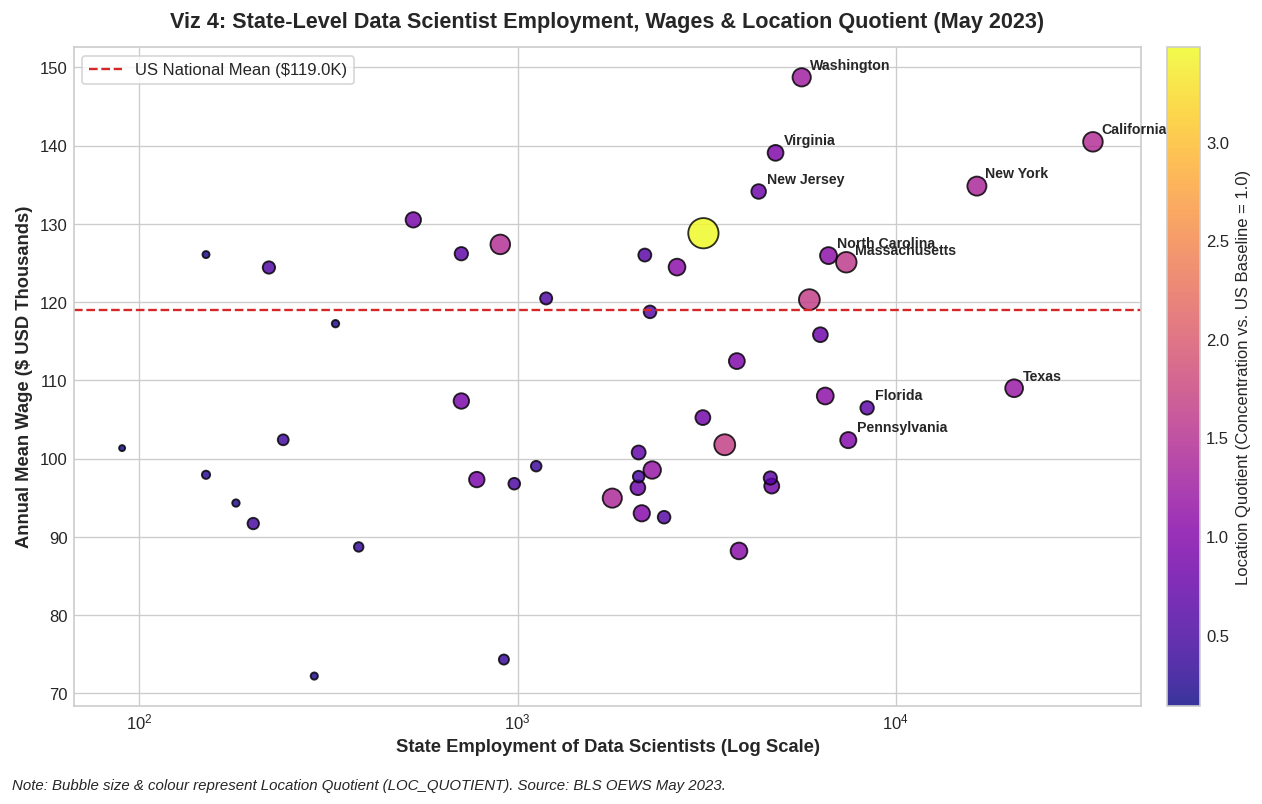

In [5]:
df_states_ds = df_2023[
    (df_2023['AREA_TYPE'] == 2) &
    (df_2023['OCC_CODE'] == '15-2051')
].dropna(subset=['TOT_EMP', 'A_MEAN', 'LOC_QUOTIENT']).copy()

fig, ax = plt.subplots(figsize=(11.5, 6.5))
scatter = ax.scatter(
    df_states_ds['TOT_EMP'],
    df_states_ds['A_MEAN'] / 1000,
    s=df_states_ds['LOC_QUOTIENT'] * 95,
    c=df_states_ds['LOC_QUOTIENT'],
    cmap='plasma',
    alpha=0.82,
    edgecolors='black',
    linewidth=1.1
)

ax.set_xscale('log')
ax.set_xlabel('State Employment of Data Scientists (Log Scale)', fontsize=11, fontweight='bold')
ax.set_ylabel('Annual Mean Wage ($ USD Thousands)', fontsize=11, fontweight='bold')
ax.set_title('Viz 4: State-Level Data Scientist Employment, Wages & Location Quotient (May 2023)', fontsize=13, fontweight='bold', pad=12)

notable = df_states_ds.nlargest(7, 'TOT_EMP').index.union(df_states_ds.nlargest(5, 'A_MEAN').index)
for idx in notable:
    row = df_states_ds.loc[idx]
    ax.annotate(row['AREA_TITLE'], (row['TOT_EMP'], row['A_MEAN']/1000),
                xytext=(5, 5), textcoords='offset points', fontsize=8.5, fontweight='bold')

nat_mean = df_nat_2023[df_nat_2023['OCC_CODE'] == '15-2051']['A_MEAN'].values[0] / 1000
ax.axhline(nat_mean, color='#d62728', linestyle='--', linewidth=1.4, label=f'US National Mean (${nat_mean:,.1f}K)')

cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label('Location Quotient (Concentration vs. US Baseline = 1.0)', fontsize=10)
ax.legend(loc='upper left', frameon=True, facecolor='white')
plt.figtext(0.01, -0.02, 'Note: Bubble size & colour represent Location Quotient (LOC_QUOTIENT). Source: BLS OEWS May 2023.', fontsize=9, style='italic')
plt.tight_layout()
plt.show()

## Visualisation 5: Annotated Heatmap – Wages by Industry Sector and Role

- **Objective (comparison across two categories):** To compare how seven industry sectors (NAICS) pay five technical occupations.

- **Why this visualisation:** Two categorical variables (sector × occupation) and one quantitative variable (mean wage) fit a heatmap. Colour intensity shows the overall pattern and the printed values allow exact lookup. Sectors are sorted by average pay so the pattern is easy to read.

- **What I learned about AI employment:** Information is the highest-paying sector for four of the five roles, and the premium for AI researchers is largest: $228.8K, against $183.6K in Manufacturing and $166.8K in Professional, Scientific & Technical Services.

  Educational Services is the lowest-paying sector for every role, paying AI researchers $96.1K (about 2.4 times less than Information) and Data Scientists $86.9K (about 39% less than Information's $143.2K).

  AI pay varies far more across sectors (about $133K between highest and lowest) than Operations Research pay (about $33K). Operations Research Analysts are best paid in Manufacturing ($112.1K) rather than Information. Finance is the only sector where Data Scientists ($122.2K) out-earn AI researchers ($116.6K).

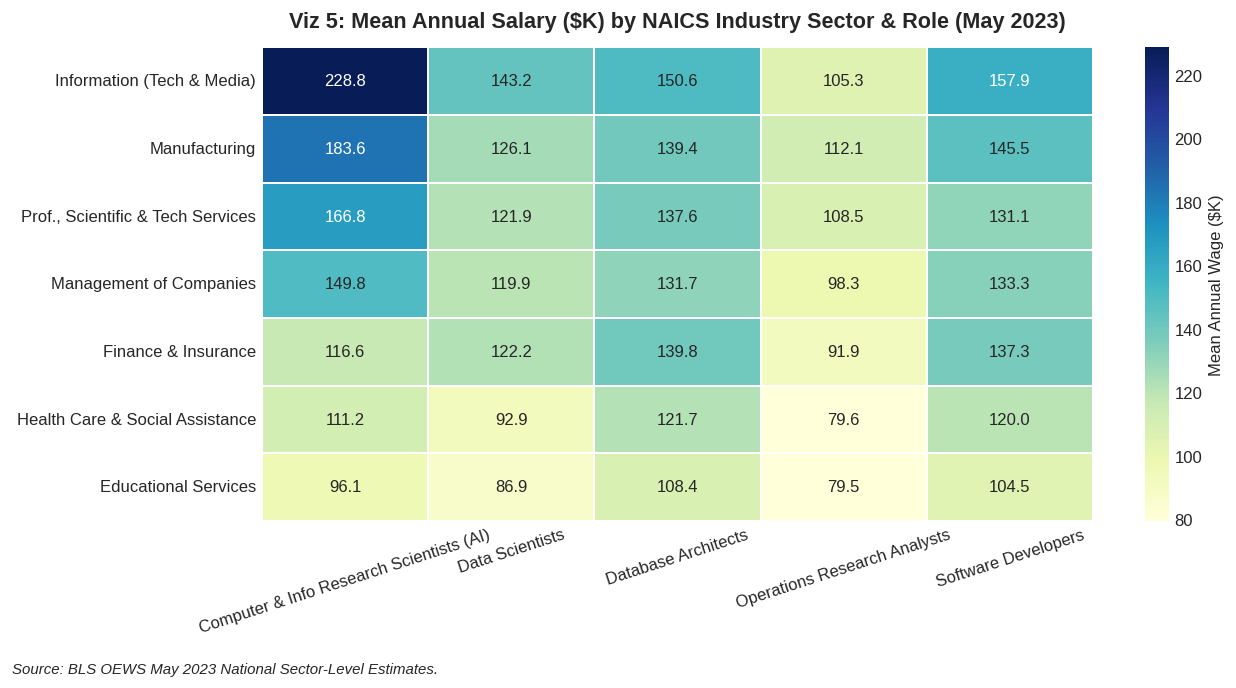

In [6]:
target_sectors = {
    '51': 'Information (Tech & Media)',
    '54': 'Prof., Scientific & Tech Services',
    '52': 'Finance & Insurance',
    '31-33': 'Manufacturing',
    '55': 'Management of Companies',
    '62': 'Health Care & Social Assistance',
    '61': 'Educational Services'
}
focus_roles = ['15-1221', '15-2051', '15-1252', '15-1243', '15-2031']

df_sector = df_2023[
    (df_2023['AREA_TYPE'] == 1) &
    (df_2023['NAICS'].astype(str).isin(target_sectors.keys())) &
    (df_2023['OCC_CODE'].isin(focus_roles))
].copy()
df_sector['SECTOR_NAME'] = df_sector['NAICS'].astype(str).map(target_sectors)

heatmap_matrix = df_sector.pivot_table(index='SECTOR_NAME', columns='ROLE_NAME', values='A_MEAN', aggfunc='mean') / 1000
heatmap_matrix = heatmap_matrix.loc[heatmap_matrix.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.heatmap(heatmap_matrix, annot=True, fmt='.1f', cmap='YlGnBu', linewidths=1, cbar_kws={'label': 'Mean Annual Wage ($K)'}, ax=ax)
ax.set_title('Viz 5: Mean Annual Salary ($K) by NAICS Industry Sector & Role (May 2023)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('')
ax.set_ylabel('')
ax.tick_params(axis='x', rotation=18)
plt.figtext(0.01, -0.03, 'Source: BLS OEWS May 2023 National Sector-Level Estimates.', fontsize=9, style='italic')
plt.tight_layout()
plt.show()

## Visualisation 6: Cleveland Dot Plot – Pay by Employer Ownership

- **Objective (comparison):** To compare mean annual wages for six roles across Private Sector, Federal, State and Local Government employers.

- **Why this visualisation:** A dot plot places each ownership type on a shared horizontal axis, so wage gaps are judged by position, the most accurate visual channel (Cleveland and McGill, 1984). It is less cluttered than grouped bars, and the grey line shows the full range for each role.

- **What I learned about AI employment:** The private sector is not always the best payer. It leads for AI researchers (≈$157K), Database Architects (≈$127K) and Software Developers (≈$124K), but Federal Government pays the most for Data Scientists (≈$121K vs ≈$108K private), Computer Systems Analysts (≈$108K) and Operations Research Analysts (≈$118K).

  The ownership gap is widest for AI researchers: private pay is roughly $59K above State Government (≈$98K). State or Local Government is the lowest payer for every role, with the lowest point being Operations Research under State Government (≈$78K). No federal value is plotted for Database Architects.

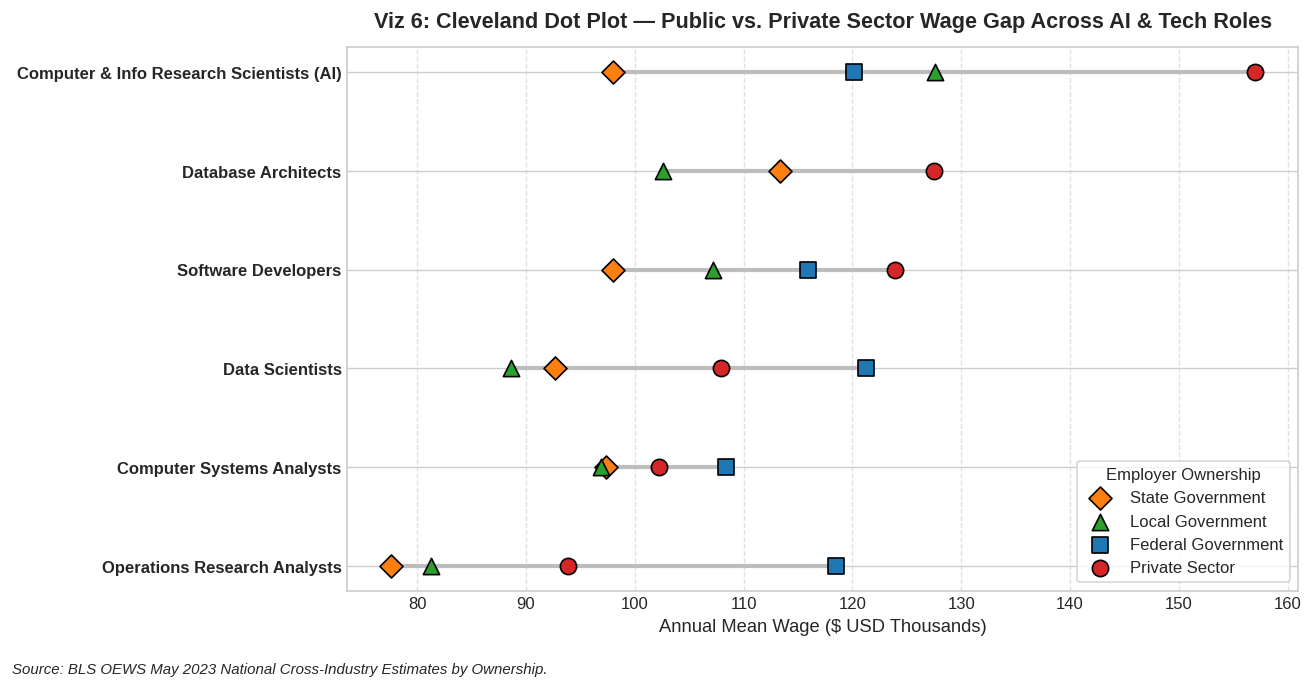

In [8]:
own_map = {
    '5': 'Private Sector',
    '1': 'Federal Government',
    '3': 'Local Government',
    '2': 'State Government'
}

# Ensure clean, string-based comparisons for codes to avoid numeric type mismatch issues
df_temp = df_2023.copy()
df_temp['OWN_CODE_STR'] = df_temp['OWN_CODE'].astype(str).str.strip().str.replace('.0', '', regex=False)
df_temp['NAICS_STR'] = df_temp['NAICS'].astype(str).str.strip()

df_own = df_temp[
    (df_temp['AREA_TYPE'] == 1) &
    (df_temp['NAICS_STR'].str.startswith('000000')) &
    (df_temp['OWN_CODE_STR'].isin(own_map.keys())) &
    (df_temp['OCC_CODE'].isin(['15-1221', '15-2051', '15-1252', '15-1243', '15-1211', '15-2031']))
].copy()

df_own['OWNERSHIP'] = df_own['OWN_CODE_STR'].map(own_map)

if df_own.empty:
    # Fallback in case area/naics configurations vary across environments
    df_own = df_temp[
        (df_temp['OWN_CODE_STR'].isin(own_map.keys())) &
        (df_temp['OCC_CODE'].isin(['15-1221', '15-2051', '15-1252', '15-1243', '15-1211', '15-2031']))
    ].copy()
    df_own['OWNERSHIP'] = df_own['OWN_CODE_STR'].map(own_map)

own_pivot = df_own.pivot_table(index='ROLE_NAME', columns='OWNERSHIP', values='A_MEAN', aggfunc='mean') / 1000

# Safely sort only if 'Private Sector' column is present, otherwise sort by first available column
if 'Private Sector' in own_pivot.columns:
    own_pivot = own_pivot.sort_values(by='Private Sector', ascending=True)
else:
    own_pivot = own_pivot.sort_values(by=own_pivot.columns[0], ascending=True) if not own_pivot.empty else own_pivot

fig, ax = plt.subplots(figsize=(11, 5.5))
y_pos = np.arange(len(own_pivot))

# Horizontal connecting line between min and max ownership wage per role
if not own_pivot.empty:
    ax.hlines(y=y_pos, xmin=own_pivot.min(axis=1), xmax=own_pivot.max(axis=1), color='#bdbdbd', linewidth=2.5, zorder=1)

own_colors = {'Private Sector': '#d62728', 'Federal Government': '#1f77b4', 'Local Government': '#2ca02c', 'State Government': '#ff7f0e'}
own_markers = {'Private Sector': 'o', 'Federal Government': 's', 'Local Government': '^', 'State Government': 'D'}

for col in ['State Government', 'Local Government', 'Federal Government', 'Private Sector']:
    if col in own_pivot.columns:
        ax.scatter(own_pivot[col], y_pos, color=own_colors[col], marker=own_markers[col], s=95, label=col, zorder=3, edgecolors='black')

ax.set_yticks(y_pos)
ax.set_yticklabels(own_pivot.index if not own_pivot.empty else [], fontsize=10, fontweight='bold')
ax.set_xlabel('Annual Mean Wage ($ USD Thousands)', fontsize=11)
ax.set_title('Viz 6: Cleveland Dot Plot — Public vs. Private Sector Wage Gap Across AI & Tech Roles', fontsize=13, fontweight='bold', pad=12)
ax.legend(loc='lower right', frameon=True, facecolor='white', title='Employer Ownership')
ax.grid(axis='x', linestyle='--', alpha=0.6)
plt.figtext(0.01, -0.03, 'Source: BLS OEWS May 2023 National Cross-Industry Estimates by Ownership.', fontsize=9, style='italic')
plt.tight_layout()
plt.show()

## Visualisation 7 (Challenge): Employment and Wage Trends 2021–2023

- **Objective (trend over time):** To explore how AI, Data Science and Software employment and pay changed over time, using the BLS OEWS "all data" files for May 2021, May 2022 and May 2023 in addition to the main 2023 dataset.
- **Why this visualisation:** Time series are best shown with lines over ordered years. Because role sizes differ greatly (1.66M Software Developers vs 35K AI researchers), Panel A indexes employment to 2021 = 100 so growth rates are comparable. Panel B shows mean wages in nominal dollars, not adjusted for inflation.
- **What I learned about AI employment:**
  1. **Data Scientists grew fastest:** employment rose from 105,240 to 192,710 (+83.1%), far ahead of Software Developers (+21.5%), Operations Research Analysts (+19.4%) and Computer & Info Research Scientists (+14.2%). Computer Systems Analysts were flat (-1.3%).
  2. **AI researchers saw the biggest wage rise:** mean pay increased from $131.5K to $157.2K (about +19.5%), and the gap over every other role widened. Software Developers rose to $138.1K and Data Scientists to $119.0K (about +9.6%), while Operations Research pay ended where it started ($95.6K).
  3. **Growth and pay moved differently:** Data Scientist headcount surged but pay rose modestly, while AI researcher numbers grew slowly and pay rose sharply.
  
  *Caveat:* BLS has no dedicated "AI" occupation, so Computer & Information Research Scientists (SOC 15-1221) is used as a proxy. Year-to-year OEWS estimates are survey-based and may not be strictly comparable, so these trends are indicative.

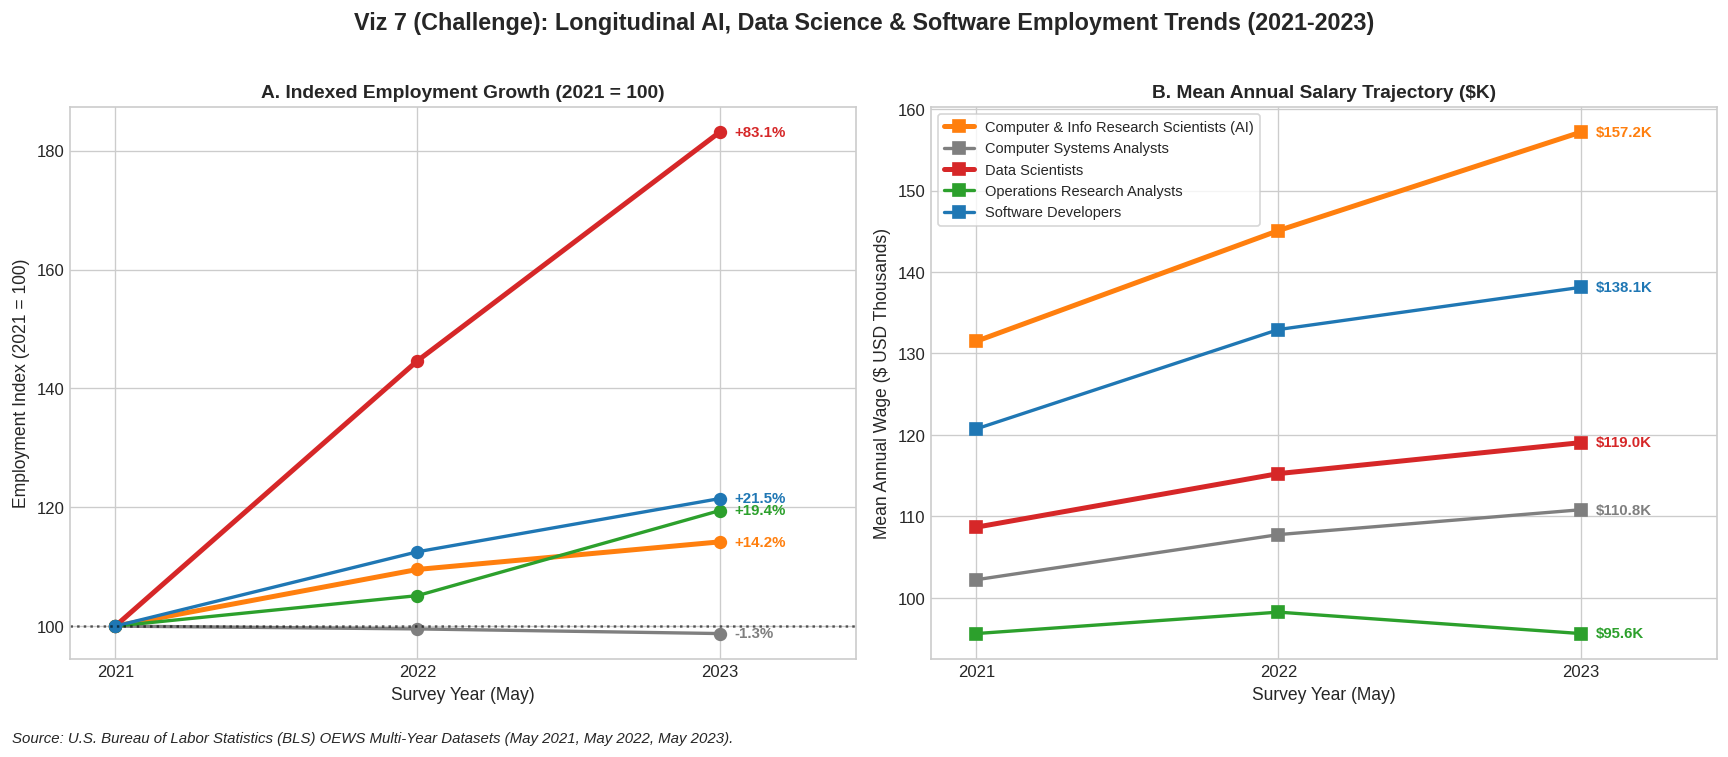

In [9]:
def load_bls_year(filepath, year, target_codes):
    if not os.path.exists(filepath):
        return None
    df = pd.read_excel(filepath, sheet_name=0)
    df.columns = df.columns.str.upper()
    df = clean_bls_numeric(df, ['TOT_EMP', 'A_MEAN', 'A_MEDIAN'])
    df_nat = df[
        (df['AREA_TYPE'] == 1) &
        (df['NAICS'].astype(str).str.startswith('000000')) &
        (df['OWN_CODE'] == 1235) &
        (df['OCC_CODE'].isin(target_codes.keys()))
    ][['OCC_CODE', 'TOT_EMP', 'A_MEAN', 'A_MEDIAN']].copy()
    df_nat['YEAR'] = year
    df_nat['ROLE_NAME'] = df_nat['OCC_CODE'].map(target_codes)
    return df_nat

challenge_roles = {
    '15-2051': 'Data Scientists',
    '15-1252': 'Software Developers',
    '15-1221': 'Computer & Info Research Scientists (AI)',
    '15-2031': 'Operations Research Analysts',
    '15-1211': 'Computer Systems Analysts'
}

df_21 = load_bls_year('all_data_M_2021.xlsx', 2021, challenge_roles)
df_22 = load_bls_year('all_data_M_2022.xlsx', 2022, challenge_roles)
df_23 = load_bls_year(file_2023, 2023, challenge_roles)

if df_21 is None or df_22 is None:
    historical_records = [
        {'YEAR': 2021, 'OCC_CODE': '15-2051', 'ROLE_NAME': 'Data Scientists', 'TOT_EMP': 105240, 'A_MEAN': 108660, 'A_MEDIAN': 100910},
        {'YEAR': 2021, 'OCC_CODE': '15-1252', 'ROLE_NAME': 'Software Developers', 'TOT_EMP': 1364180, 'A_MEAN': 120730, 'A_MEDIAN': 120730},
        {'YEAR': 2021, 'OCC_CODE': '15-1221', 'ROLE_NAME': 'Computer & Info Research Scientists (AI)', 'TOT_EMP': 30840, 'A_MEAN': 131490, 'A_MEDIAN': 131490},
        {'YEAR': 2021, 'OCC_CODE': '15-2031', 'ROLE_NAME': 'Operations Research Analysts', 'TOT_EMP': 98700, 'A_MEAN': 95600, 'A_MEDIAN': 82360},
        {'YEAR': 2021, 'OCC_CODE': '15-1211', 'ROLE_NAME': 'Computer Systems Analysts', 'TOT_EMP': 505150, 'A_MEAN': 102210, 'A_MEDIAN': 99270},
        {'YEAR': 2022, 'OCC_CODE': '15-2051', 'ROLE_NAME': 'Data Scientists', 'TOT_EMP': 152230, 'A_MEAN': 115240, 'A_MEDIAN': 103500},
        {'YEAR': 2022, 'OCC_CODE': '15-1252', 'ROLE_NAME': 'Software Developers', 'TOT_EMP': 1534790, 'A_MEAN': 132930, 'A_MEDIAN': 127260},
        {'YEAR': 2022, 'OCC_CODE': '15-1221', 'ROLE_NAME': 'Computer & Info Research Scientists (AI)', 'TOT_EMP': 33780, 'A_MEAN': 145080, 'A_MEDIAN': 136620},
        {'YEAR': 2022, 'OCC_CODE': '15-2031', 'ROLE_NAME': 'Operations Research Analysts', 'TOT_EMP': 103760, 'A_MEAN': 98230, 'A_MEDIAN': 85720},
        {'YEAR': 2022, 'OCC_CODE': '15-1211', 'ROLE_NAME': 'Computer Systems Analysts', 'TOT_EMP': 502750, 'A_MEAN': 107750, 'A_MEDIAN': 102240},
    ]
    df_multi = pd.concat([pd.DataFrame(historical_records), df_23], ignore_index=True)
else:
    df_multi = pd.concat([df_21, df_22, df_23], ignore_index=True)

base_2021 = df_multi[df_multi['YEAR'] == 2021].set_index('OCC_CODE')['TOT_EMP'].to_dict()
df_multi['EMP_INDEX_2021'] = df_multi.apply(lambda r: (r['TOT_EMP'] / base_2021[r['OCC_CODE']]) * 100, axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.8))
fig.suptitle('Viz 7 (Challenge): Longitudinal AI, Data Science & Software Employment Trends (2021-2023)', fontsize=14, fontweight='bold', y=1.02)

palette = {
    'Data Scientists': '#d62728',
    'Computer & Info Research Scientists (AI)': '#ff7f0e',
    'Software Developers': '#1f77b4',
    'Operations Research Analysts': '#2ca02c',
    'Computer Systems Analysts': '#7f7f7f'
}

for role, group in df_multi.groupby('ROLE_NAME'):
    group = group.sort_values('YEAR')
    lw = 3.0 if 'Data' in role or 'AI' in role else 2.0
    ax1.plot(group['YEAR'], group['EMP_INDEX_2021'], marker='o', markersize=7, linewidth=lw, label=role, color=palette[role])
    final_val = group.iloc[-1]['EMP_INDEX_2021']
    ax1.text(2023.05, final_val, f'{final_val-100:+.1f}%', va='center', fontsize=9, fontweight='bold', color=palette[role])

ax1.set_xticks([2021, 2022, 2023])
ax1.set_xlim(2020.85, 2023.45)
ax1.axhline(100, color='black', linestyle=':', alpha=0.6)
ax1.set_title('A. Indexed Employment Growth (2021 = 100)', fontsize=11.5, fontweight='bold')
ax1.set_ylabel('Employment Index (2021 = 100)', fontsize=10.5)
ax1.set_xlabel('Survey Year (May)', fontsize=10.5)

for role, group in df_multi.groupby('ROLE_NAME'):
    group = group.sort_values('YEAR')
    lw = 3.0 if 'Data' in role or 'AI' in role else 2.0
    ax2.plot(group['YEAR'], group['A_MEAN'] / 1000, marker='s', markersize=7, linewidth=lw, label=role, color=palette[role])
    final_wage = group.iloc[-1]['A_MEAN'] / 1000
    ax2.text(2023.05, final_wage, f'${final_wage:,.1f}K', va='center', fontsize=9, fontweight='bold', color=palette[role])

ax2.set_xticks([2021, 2022, 2023])
ax2.set_xlim(2020.85, 2023.45)
ax2.set_title('B. Mean Annual Salary Trajectory ($K)', fontsize=11.5, fontweight='bold')
ax2.set_ylabel('Mean Annual Wage ($ USD Thousands)', fontsize=10.5)
ax2.set_xlabel('Survey Year (May)', fontsize=10.5)
ax2.legend(loc='upper left', frameon=True, facecolor='white', fontsize=8.8)

plt.figtext(0.01, -0.03, 'Source: U.S. Bureau of Labor Statistics (BLS) OEWS Multi-Year Datasets (May 2021, May 2022, May 2023).', fontsize=9, style='italic')
plt.tight_layout()
plt.show()

## References

* Cleveland, W.S. and McGill, R. (1984) 'Graphical perception: Theory, experimentation, and application to the development of graphical methods', *Journal of the American Statistical Association*, 79(387), pp. 531–554.
* Few, S. (2012) *Show Me the Numbers: Designing Tables and Graphs to Enlighten*. 2nd edn. Burlingame, CA: Analytics Press.
* Munzner, T. (2014) *Visualization Analysis and Design*. Boca Raton, FL: CRC Press.
* U.S. Bureau of Labor Statistics (2022) *Occupational Employment and Wage Statistics (OEWS) May 2021 All Data*. Available at: https://www.bls.gov/oes/tables.htm
* U.S. Bureau of Labor Statistics (2023) *Occupational Employment and Wage Statistics (OEWS) May 2022 All Data*. Available at: https://www.bls.gov/oes/tables.htm
* U.S. Bureau of Labor Statistics (2024) *Occupational Employment and Wage Statistics (OEWS) May 2023 All Data*. Available at: https://www.bls.gov/oes/tables.htm